# WNBA All Game Attendance (per game)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

all_WNBA_game_data = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Mounted at /content/gdrive


In [3]:
all_WNBA_game_data.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


In [24]:
# Descriptive Statistics

# List of teams that made the 2024 WNBA playoffs
playoff_teams_2024 = [
    "New York Liberty", "Minnesota Lynx", "Connecticut Sun", "Las Vegas Aces",
    "Seattle Storm", "Indiana Fever", "Phoenix Mercury", "Atlanta Dream"
]

# Filter the data for only those teams
filtered_data = all_WNBA_game_data[all_WNBA_game_data['Home Team'].isin(playoff_teams_2024)]

# Calculate descriptive statistics for Attendance
attendance_stats = filtered_data.groupby('Home Team')['Attendance'].describe()

# Ensure the column names are properly assigned in the statistics output
attendance_stats = attendance_stats[['mean', 'std', 'min', 'max']]

# Round to remove decimals
attendance_stats = attendance_stats.round(0).astype(int)

# Display the cleaned-up table
attendance_stats


,mean,std,min,max
Home Team,,,,
Atlanta Dream,5170,2459,561,17608
Connecticut Sun,6709,1662,2012,19125
Indiana Fever,8031,3267,960,18345
Las Vegas Aces,7238,3330,1954,20366
Minnesota Lynx,8355,2882,1934,19521
New York Liberty,9851,4295,815,19563
Phoenix Mercury,9331,2566,3618,17747
Seattle Storm,8001,2548,1001,18343


In [4]:
# Group by year and calculate the mean (per game)
avg_attendance_per_year = all_WNBA_game_data.groupby("Year")["Attendance"].mean().reset_index()

# Rename columns
avg_attendance_per_year.columns = ["Year", "Average Attendance"]

print(avg_attendance_per_year)

    Year  Average Attendance
0   1997         9796.217391
1   1998        10917.835443
2   1999        10382.965686
3   2000         9311.560440
4   2001         9290.505455
5   2002         9417.343066
6   2003         8892.205426
7   2004         8659.845833
8   2005         8190.945607
9   2006         7667.232558
10  2007         8011.502058
11  2008         7986.953668
12  2009         8212.868313
13  2010         8079.389140
14  2011         8083.508929
15  2012         7605.484305
16  2013         7542.004505
17  2014         7659.991031
18  2015         7459.862832
19  2016         7731.977273
20  2017         7878.359091
21  2018         6898.031674
22  2019         6507.208145
23  2021         3096.210526
24  2022         5973.429167
25  2023         6834.835249
26  2024        10011.399240


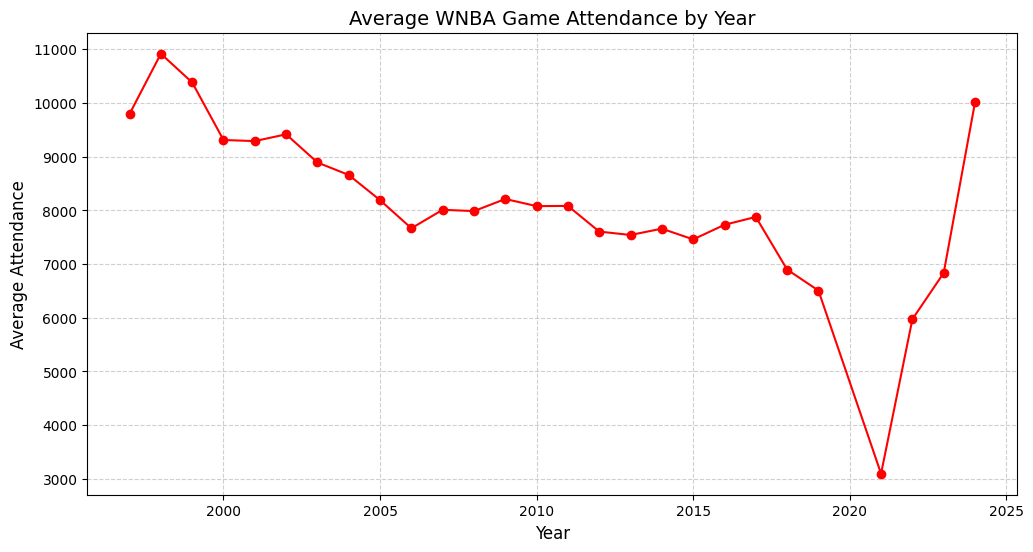

In [5]:
# Plot
plt.figure(figsize=(12, 6))
plt.plot(avg_attendance_per_year["Year"], avg_attendance_per_year["Average Attendance"], marker="o", linestyle="-", color="r")

# Titles and labels
plt.title("Average WNBA Game Attendance by Year", fontsize=14)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Attendance", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

# Plot
plt.show()

# WNBA All Game Attendance (per home team and per year)

In [6]:
# Group by year and home team, then calculate the average attendance per game
avg_attendance_per_team_year = all_WNBA_game_data.groupby(["Year", "Home Team"])["Attendance"].mean().reset_index()

# Rename columns
avg_attendance_per_team_year.columns = ["Year", "Home Team", "Average Attendance"]

avg_attendance_per_team_year['Average Attendance'] = round(avg_attendance_per_team_year['Average Attendance'], 0)
avg_attendance_per_team_year['Average Attendance'] = avg_attendance_per_team_year['Average Attendance'].astype(int)
avg_attendance_per_team_year.head()

,Year,Home Team,Average Attendance
0,1997,Charlotte Sting,8307
1,1997,Cleveland Rockers,7971
2,1997,Houston Comets,10227
3,1997,Los Angeles Sparks,8931
4,1997,New York Liberty,13270


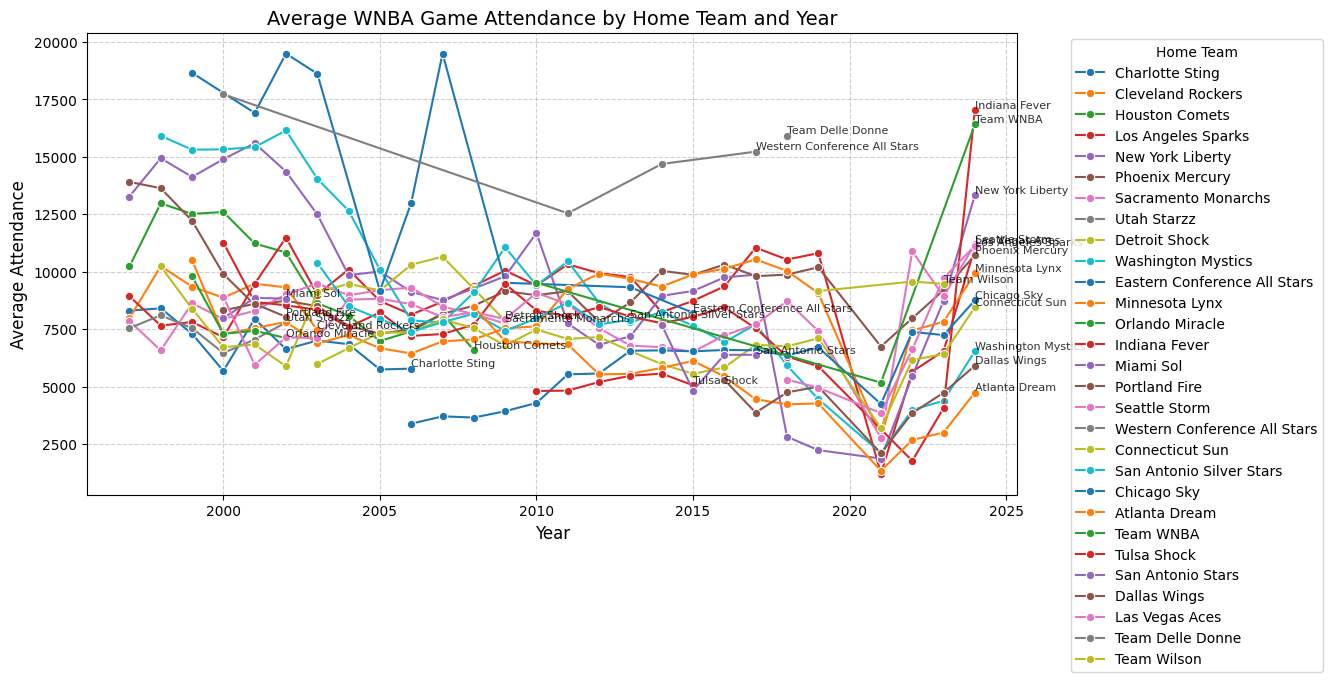

In [7]:
# Set figure size
plt.figure(figsize=(12, 6))

# Create line plot with scatter points
sns.lineplot(data=avg_attendance_per_team_year, x="Year", y="Average Attendance", hue="Home Team", marker="o", palette="tab10")

# Get the last available data point for each team
last_points = avg_attendance_per_team_year.groupby("Home Team").last().reset_index()

# Add labels only to the last data point for each team
for _, row in last_points.iterrows():
    plt.text(row["Year"], row["Average Attendance"], row["Home Team"],
             fontsize=8, ha='left', va='bottom', alpha=0.8)

# Add titles and labels
plt.title("Average WNBA Game Attendance by Home Team and Year", fontsize=14)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Attendance", fontsize=12)
plt.legend(title="Home Team", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)

# Show the plot
plt.show()

In [8]:
# Teams that are still active today

teams_in_dataset = avg_attendance_per_team_year["Home Team"].unique()

# List of currently active WNBA teams
active_teams = [
    "Atlanta Dream", "Chicago Sky", "Connecticut Sun", "Dallas Wings", "Indiana Fever",
    "Las Vegas Aces", "Los Angeles Sparks", "Minnesota Lynx", "New York Liberty",
    "Phoenix Mercury", "Seattle Storm", "Washington Mystics"
]

# Find which active teams are in the dataset
active_teams_in_dataset = [team for team in teams_in_dataset if team in active_teams]

# Filter the dataset to include only active teams
filtered_df = avg_attendance_per_team_year[avg_attendance_per_team_year['Home Team'].isin(active_teams)]

# Display the filtered dataset
filtered_df.head()

,Year,Home Team,Average Attendance
3,1997,Los Angeles Sparks,8931
4,1997,New York Liberty,13270
5,1997,Phoenix Mercury,13906
12,1998,Los Angeles Sparks,7653
13,1998,New York Liberty,14935


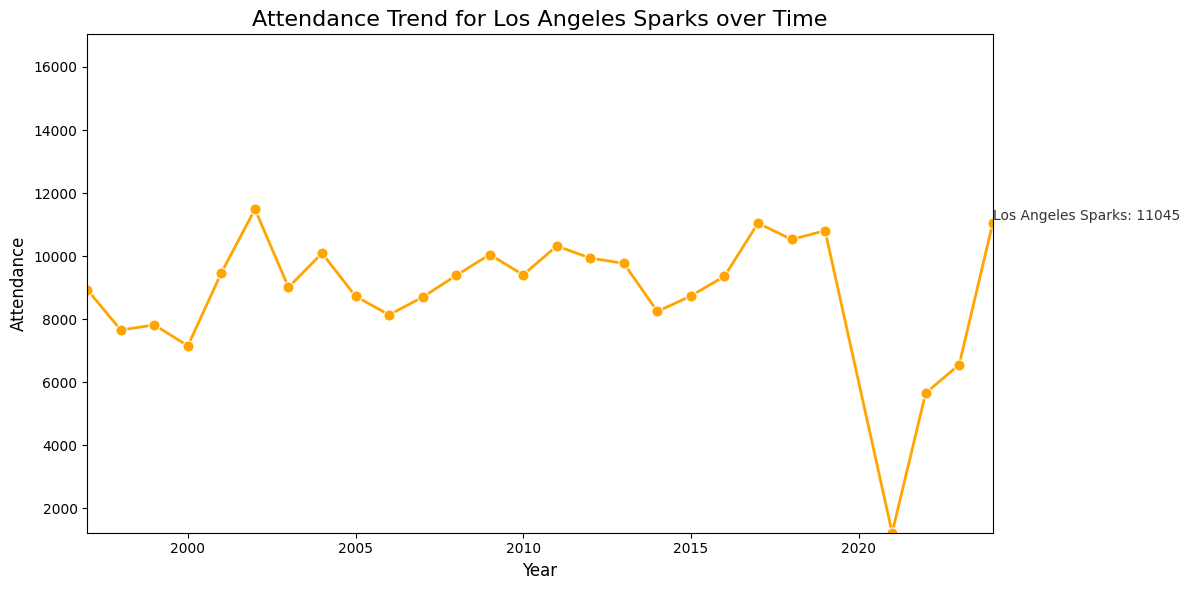

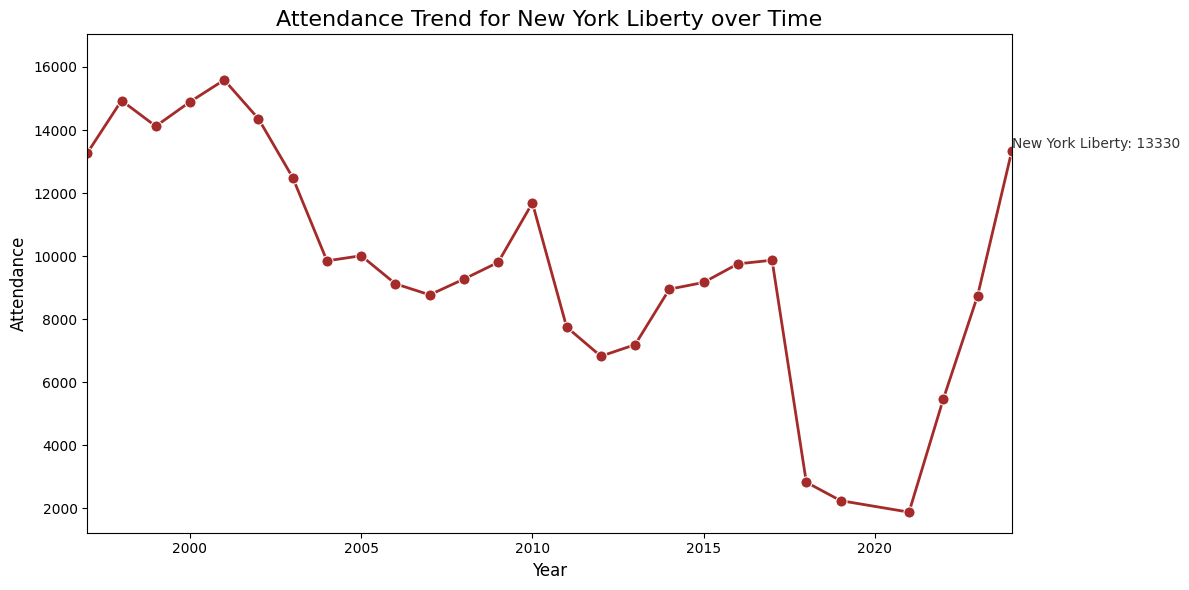

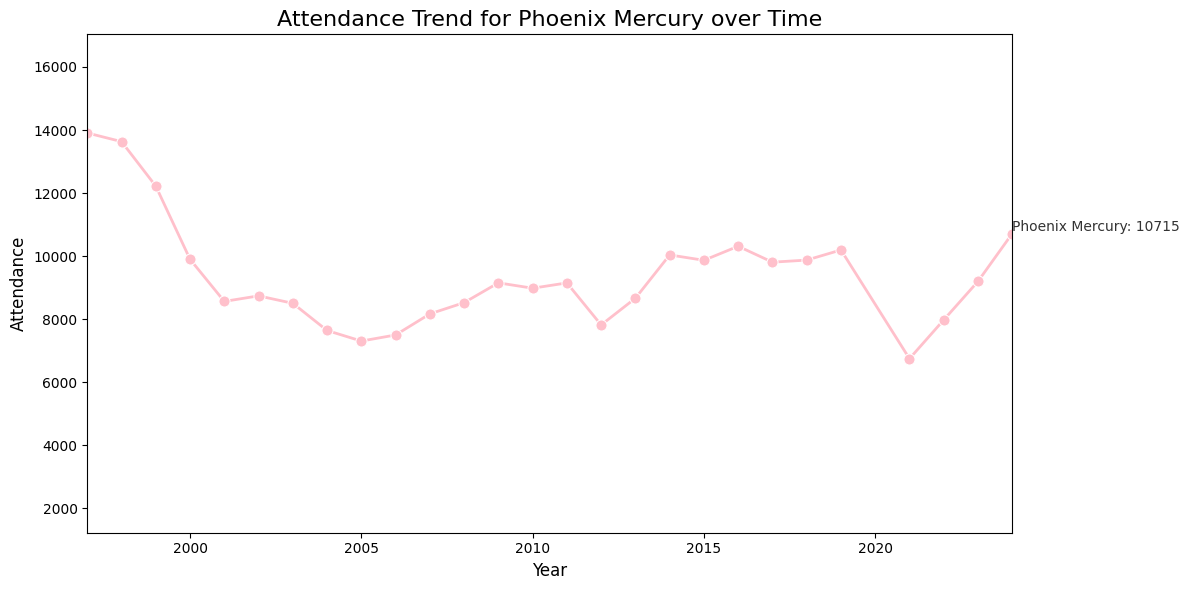

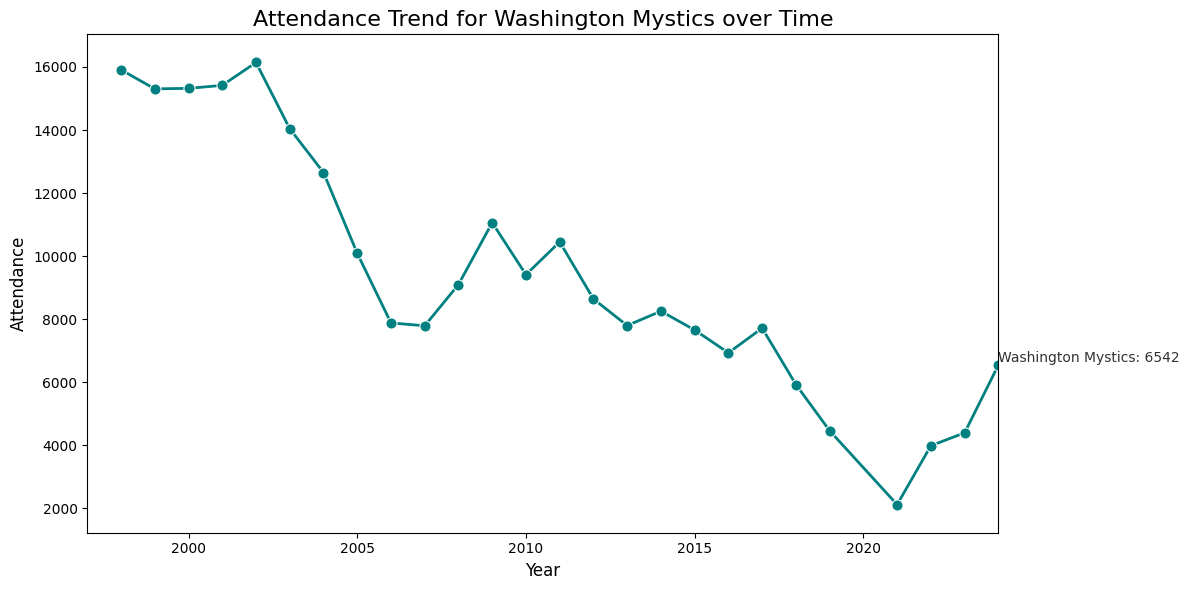

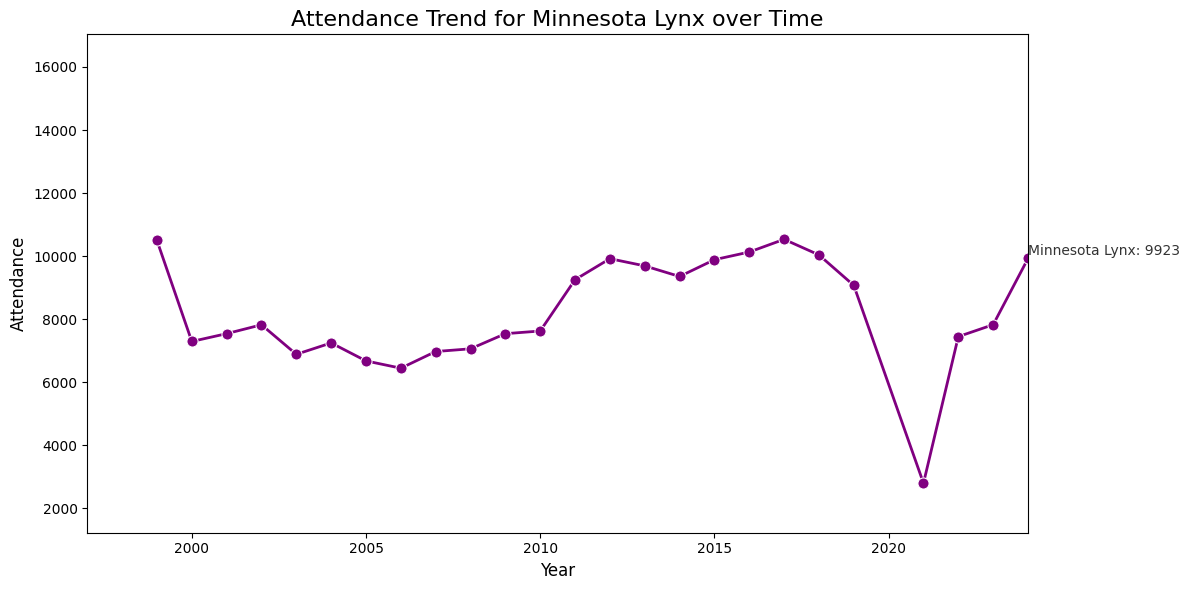

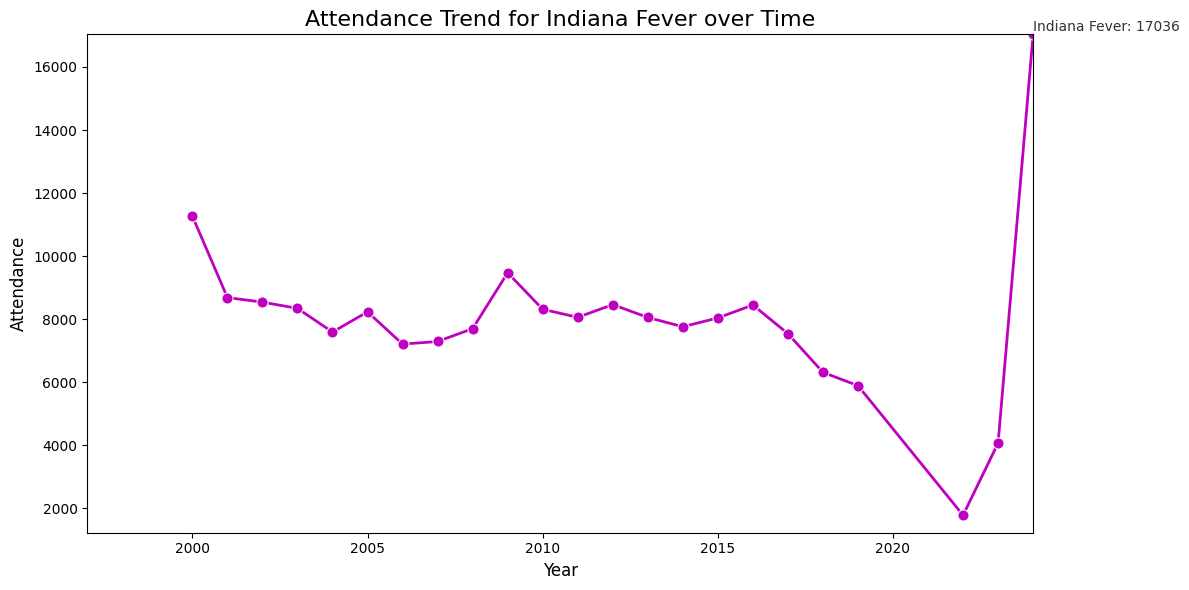

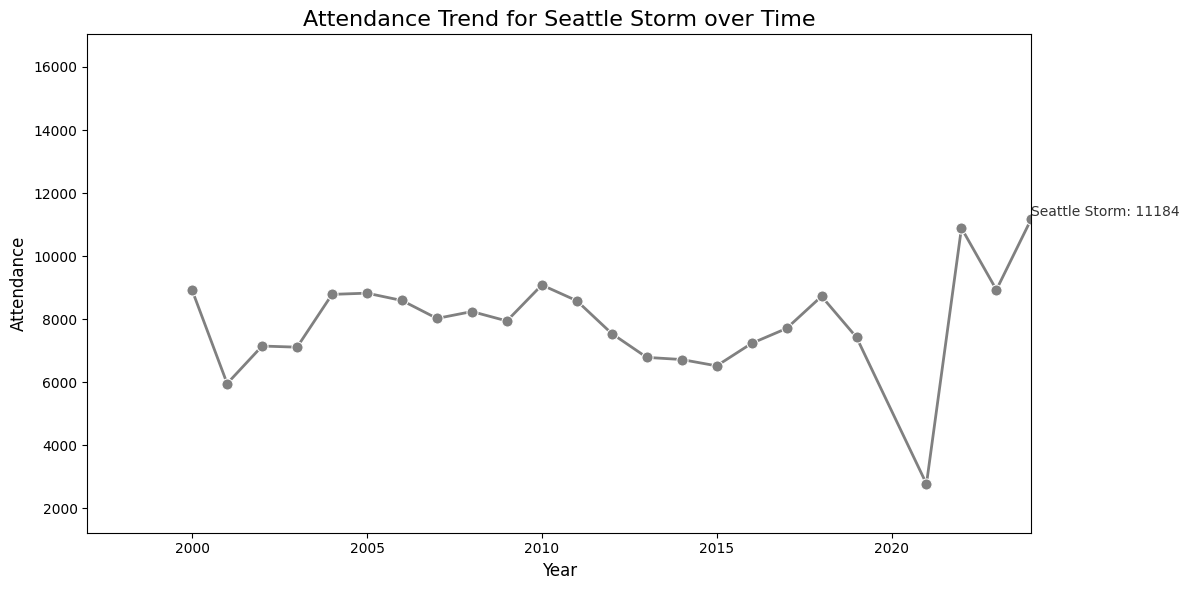

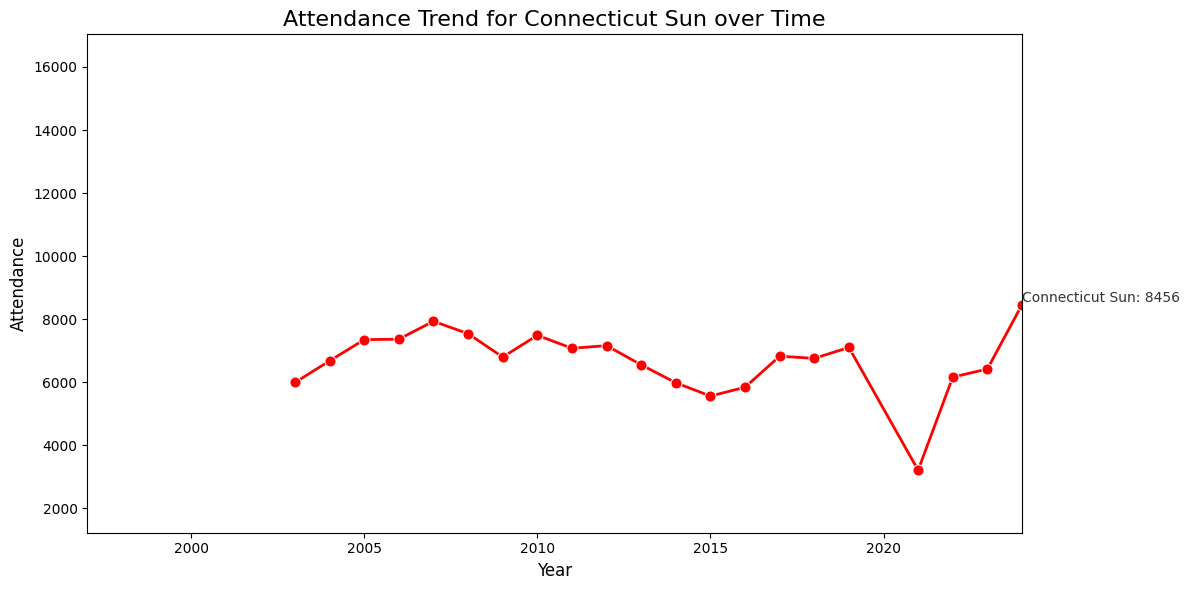

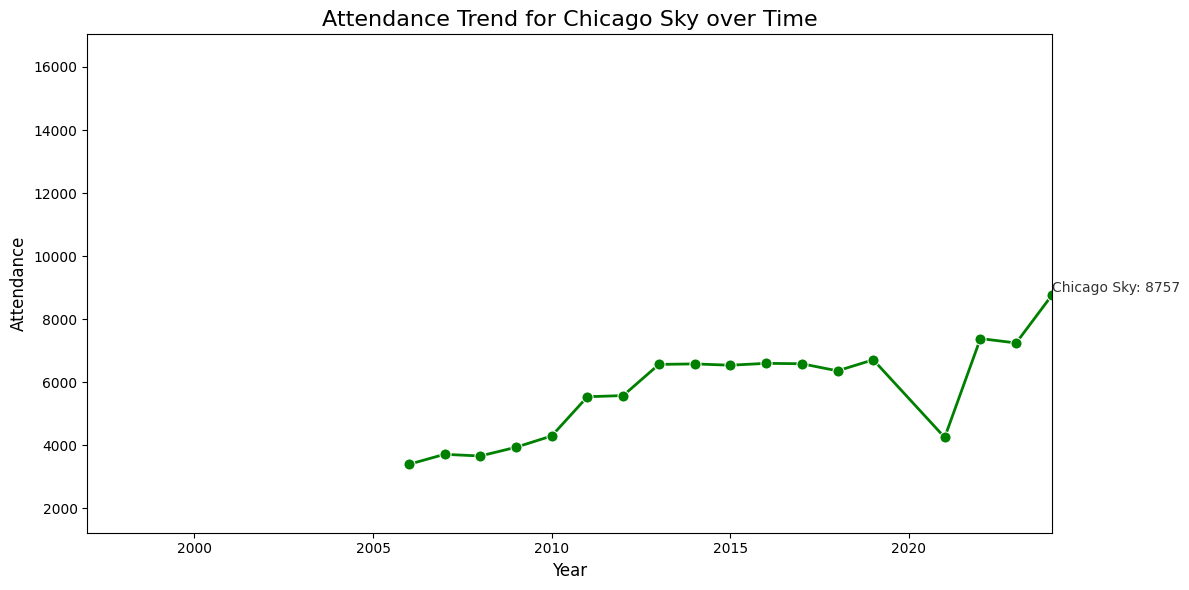

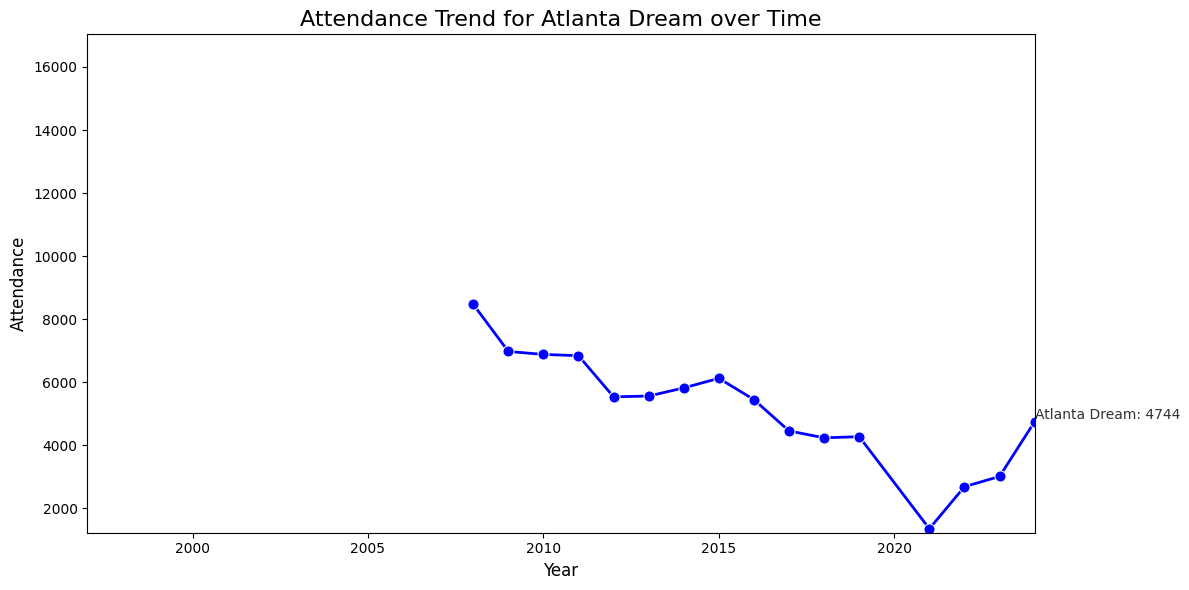

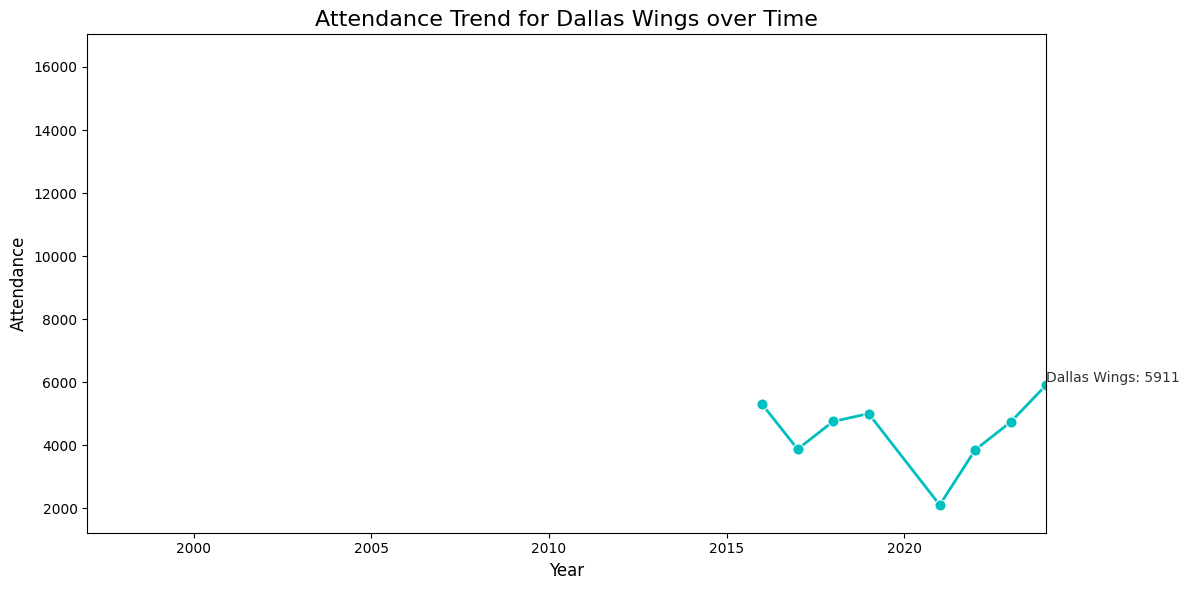

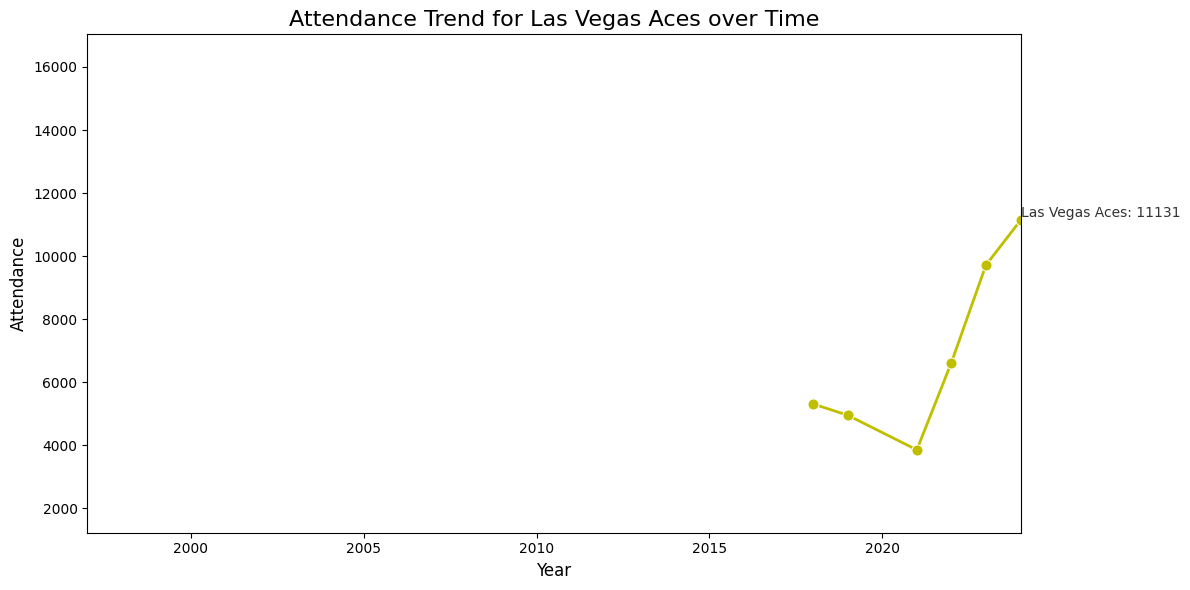

In [9]:
# Define a color palette (you can customize this further)
team_colors = {
    "Atlanta Dream": "b",      # Blue
    "Chicago Sky": "g",        # Green
    "Connecticut Sun": "r",    # Red
    "Dallas Wings": "c",       # Cyan
    "Indiana Fever": "m",      # Magenta
    "Las Vegas Aces": "y",     # Yellow
    "Los Angeles Sparks": "orange",  # Orange
    "Minnesota Lynx": "purple",  # Purple
    "New York Liberty": "brown",  # Brown
    "Phoenix Mercury": "pink",  # Pink
    "Seattle Storm": "gray",   # Gray
    "Washington Mystics": "teal"  # Teal
}

# Set the same axis limits for all plots
# Define the limits for Year and Attendance (adjust based on your data)
xlim = (filtered_df['Year'].min(), filtered_df['Year'].max())
ylim = (filtered_df['Average Attendance'].min(), filtered_df['Average Attendance'].max())

# Create separate line plots for each active team
for team in active_teams_in_dataset:
    team_data = filtered_df[filtered_df['Home Team'] == team]

    # Use the color associated with the team
    team_color = team_colors.get(team, "b")  # Default to blue if no color is found

    # Create a line plot for the team with its specific color and no confidence intervals
    plt.figure(figsize=(12, 6))
    sns.lineplot(data=team_data, x='Year', y='Average Attendance', marker='o', color=team_color, linewidth=2, markersize=8, errorbar=None)

    # Add labels only to the year 2024 average game attendance (AVERAGE)
    last_point = team_data.iloc[-1]
    plt.text(last_point["Year"], last_point["Average Attendance"], f"{team}: {last_point['Average Attendance']}",
             fontsize=10, ha='left', va='bottom', alpha=0.8)

    # Set the x and y limits to be the same for all plots
    plt.xlim(xlim)
    plt.ylim(ylim)

    # Customizing the plot
    plt.title(f'Attendance Trend for {team} over Time', fontsize=16)
    plt.xlabel('Year', fontsize=12)
    plt.ylabel('Attendance', fontsize=12)

    # Display the plot
    plt.tight_layout()
    plt.show()

# Regular Season Viewers


In [10]:
WNBA_regular_season_viewer_data = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA Regular Season TV Viewers - Data.csv')

In [11]:
WNBA_regular_season_viewer_data.head()

,WNBA Regular Season TV Viewers,Average TV viewership of the WNBA regular season from 2016 to 2024
0,2016,224000
1,2017,171000
2,2018,231000
3,2019,246000
4,2020,205000


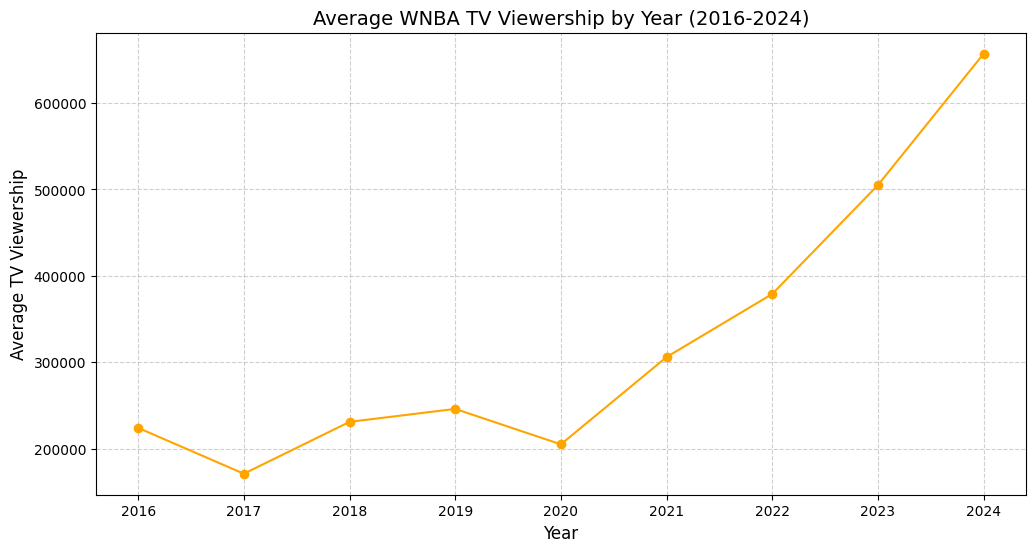

In [12]:
# Rename columns
WNBA_regular_season_viewer_data.columns = ['Year', 'Viewers']

# Data
plt.figure(figsize=(12, 6))
plt.plot(WNBA_regular_season_viewer_data['Year'], WNBA_regular_season_viewer_data['Viewers'], marker='o', linestyle='-', color='orange')

# Titles and labels
plt.title("Average WNBA TV Viewership by Year (2016-2024)", fontsize=14)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average TV Viewership", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

# Plot
plt.show()

# Finals Viewers

In [13]:
WNBA_finals_viewer_data = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA Finals TV Viewership - Data.csv')

In [14]:
WNBA_finals_viewer_data.head()

,WNBA Finals TV viewership,Number of TV viewers of the WNBA Finals from 1997 to 2024
0,1997,2850000
1,1998,1580000
2,1999,2020000
3,2000,1540000
4,2001,966000


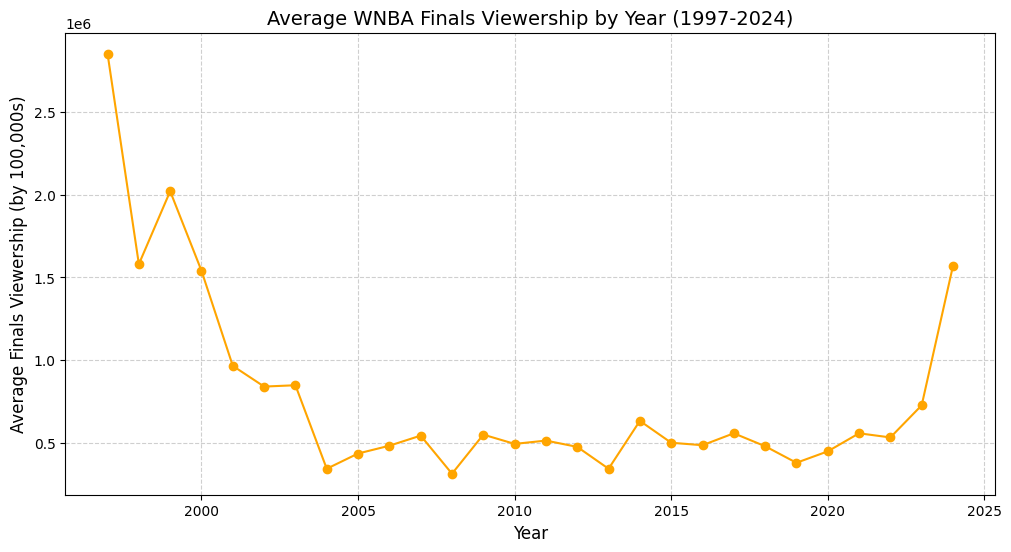

In [15]:
# Rename columns
WNBA_finals_viewer_data.columns = ['Year', 'Viewers']

# Data
plt.figure(figsize=(12, 6))
plt.plot(WNBA_finals_viewer_data['Year'], WNBA_finals_viewer_data['Viewers'], marker='o', linestyle='-', color='orange')

# Titles and labels
plt.title("Average WNBA Finals Viewership by Year (1997-2024)", fontsize=14)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Finals Viewership (by 100,000s)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

# Plot
plt.show()